<a href="https://colab.research.google.com/github/armandoordonez/eda_couse/blob/main/EDA_Guia_Automoviles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MIAAP - Análisis De Datos I
#TALLER 1
#Análisis Exploratorio de Datos (EDA) para la Estimación de Esfuerzo en Iniciativas de Software

**Integrantes**
* Laura Mercedez Lara Rocha
* Juan Fernando Gutierrez Castrillon
* Ivan Ortiz
* Miguel Angel Paz Velasco
* Carlos Alberto Salamando Mejia


## Caso: Estimacion de proyectos de software en banca

---

Este cuaderno constituye una **guía metodológica completa** que reproduce, paso a paso, el flujo general de trabajo presentado en clase. El objetivo pedagógico es que el estudiante comprenda no solamente *cómo* se ejecuta cada instrucción, sino *por qué* se ejecuta y *qué decisión de negocio* respalda cada una de ellas.

El flujo que seguiremos es el siguiente:

> **Pregunta SMART + Hipótesis → Diccionario de datos → Visión general → Limpieza → Análisis univariado → Análisis bivariado → Conclusiones**

En cada sección se indicará de manera explícita a qué etapa del flujo corresponde, con el fin de mantener la trazabilidad entre la teoría vista en la presentación y su implementación práctica.

---
# 1. El Problema de Negocio y la Pregunta SMART

> *Etapa del flujo: **Pregunta SMART + Hipótesis***

Antes de analizar datos o entrenar modelos, el análisis debe delimitarse a un problema concreto de ingeniería y gestión de TI.
## 1.1. Contexto del Negocio

**El problema.** En la Gerencia de Tecnología de una entidad financiera, las iniciativas de software se estiman inicialmente en horas antes de iniciar su desarrollo. Sin embargo, existe una desviación recurrente entre el **esfuerzo estimado** al inicio de la iniciativa y el **esfuerzo real** (`horas_reales`) consumido durante su ejecución. Esta desviación no es marginal ni aleatoria: afecta de forma sistemática la planeación de capacidad de los equipos y genera un efecto en cascada sobre los compromisos de entrega del portafolio completo.

**Áreas y procesos afectados:**
- **Capítulos de Arquitectura e Ingeniería de Software:** responsables de dimensionar la complejidad técnica (`complejidad_propuesta`, `patron_arquitectura`) antes de iniciar el desarrollo. Sus estimaciones iniciales son las que se desvían.
- **PMO / Gestión de Portafolio:** encargada de planificar la capacidad del equipo técnico y comprometer fechas de entrega con base en las estimaciones. Cuando el esfuerzo real supera lo estimado, se generan retrasos que se propagan a otras iniciativas en cola.
- **Áreas de negocio dueñas de las iniciativas** (`dominio_negocio`: Core Bancario, Riesgos, Fraude, Canales Digitales, etc.): reciben las funcionalidades con retraso frente al compromiso original, afectando sus propios cronogramas regulatorios o comerciales.

**Impacto medible.** Cuando el esfuerzo real supera significativamente al estimado, se generan sobrecostos (horas-hombre no presupuestadas) y retrasos que comprometen los planes trimestrales de entrega tecnológica. Este problema se agrava porque la estimación inicial actualmente se basa en gran medida en el juicio experto de los arquitectos, sin un respaldo cuantitativo sistemático que incorpore variables objetivas como la cantidad de integraciones o el número de aplicaciones impactadas.

**Indicador (KPI) que podría mejorarse.** El indicador propuesto es el **MAPE de Estimación de Esfuerzo** (*Mean Absolute Percentage Error*), definido como:

$$MAPE = \frac{1}{n}\sum \left| \frac{horas\_estimadas - horas\_reales}{horas\_reales} \right| \times 100\%$$

Este KPI mide, en promedio, qué tan lejos están las estimaciones iniciales del esfuerzo real, expresado como porcentaje. Al ser comparable entre iniciativas de distinto tamaño, permite fijar una meta concreta y medible ("reducir el MAPE actual en 15 puntos porcentuales para el Q4"), y es directamente accionable a partir del EDA: identificar qué variables (`cantidad_integraciones`, `apps_impactadas`) deben pesar más en el proceso de estimación para reducir este indicador.

## 1.2. Formulación de la Pregunta SMART
> **Pregunta SMART:** *"¿Es posible reducir el margen de error (MAPE) entre la estimación inicial (horas_estimadas) y el esfuerzo real (horas_reales) en un 15% para el Q4, identificando qué factores técnicos y de negocio explican mejor la variabilidad de horas_reales?"*

**Cumplimiento de los criterios SMART:**
- **Específica:** se centra en reducir el margen de error de estimación (MAPE), no en el desempeño general del área.
- **Medible:** el MAPE es un indicador numérico, calculable por iniciativa y de forma agregada.
- **Accionable:** las variables con mayor poder explicativo sobre `horas_reales` pueden incorporarse al proceso de estimación de Arquitectura.
- **Realista:** el dataset histórico contiene tanto la estimación inicial como el esfuerzo real, lo que permite calcular el MAPE actual como línea base.
- **con Temporalidad:** la meta está fijada para el cierre del Q4.

## 1.3. Hipótesis de Trabajo

- **H1:** La `cantidad_integraciones` y la `complejidad_propuesta` presentan una relación **positiva y fuerte** con las `horas_reales`, siendo factores técnicos que el proceso de estimación actual podría no estar ponderando correctamente.

- **H2:** Iniciativas que impactan un mayor número de sistemas (`apps_impactadas`) o utilizan patrones distribuidos (`Event-Driven`, `Microservicios`) demandan significativamente más horas promedio que arquitecturas simples o monolíticas.

- **H3:** Determinados dominios de negocio críticos (e.g. *Core Bancario*, *Riesgos*) presentan mayor dispersión de horas reales, lo que sugiere mayor incertidumbre y, por tanto, mayor error de estimación en ese tipo de iniciativas.

- **H4:** El `riesgo_regulatorio` y el `patron_arquitectura` presentan una relación **positiva y fuerte** con las `horas_reales`.

- **H5: El margen de error de estimación (`horas_estimadas` vs. `horas_reales`) **no es homogéneo**: es sistemáticamente mayor en iniciativas con alta `cantidad_integraciones` y alto `apps_impactadas`, lo que indica que la estimación actual subestima el esfuerzo en iniciativas técnicamente más interconectadas, más que en las de mayor "complejidad" percibida subjetivamente.

## 1.4. Complejidad y Disponibilidad de Datos

**Fuente de los datos:** El dataset (`dataset_iniciativas_softwareV2`) se origina en el sistema de gestión de proyectos e iniciativas tecnológicas de la entidad financiera (registro histórico de PMO/Arquitectura), donde se documenta tanto la estimación inicial como el esfuerzo real ejecutado por cada iniciativa cerrada.

**Complejidad del problema:** El conjunto de datos comprende 10 variables que combinan tres dominios distintos: (1) variables arquitectónicas (`patron_arquitectura`, `complejidad_propuesta`), (2) variables de integración técnica (`apps_impactadas`, `cantidad_integraciones`), y (3) variables de contexto de negocio (`dominio_negocio`, `riesgo_regulatorio`). Esta heterogeneidad implica una dificultad técnica media-alta, ya que requiere combinar variables numéricas, ordinales y categóricas nominales para explicar una única variable continua objetivo (`horas_reales`), además de manejar valores perdidos codificados de forma no estándar (`?`).

## 1.5. Justificación del Uso de IA / Ciencia de Datos

Dado que el problema busca explicar y eventualmente predecir `horas_reales` a partir de múltiples factores arquitectónicos y de negocio, un análisis manual o basado en reglas fijas resulta insuficiente frente a la cantidad de variables interactuantes. Se propone aplicar:

- **Análisis de correlación y regresión lineal múltiple**, para cuantificar qué variables (complejidad, integraciones, apps impactadas) explican en mayor medida la variabilidad de `horas_reales`.
- **Modelos de importancia de variables (ej. Random Forest / feature importance)**, que permiten capturar relaciones no lineales entre las variables arquitectónicas y el esfuerzo real, algo que un análisis puramente descriptivo no logra.

Esta combinación es pertinente porque el objetivo final no es solo describir el pasado, sino habilitar una **estimación predictiva** que reduzca el margen de error frente al esfuerzo real, respondiendo directamente a la pregunta SMART planteada.

---
<!-- # Versión Anterior
## 1.1. Contexto del Negocio
La Gerencia y los Capítulos de Arquitectura / Ingeniería de Software de una entidad financiera requieren dimensionar de forma precisa el esfuerzo y la capacidad requerida para ejecutar iniciativas tecnológicas. Históricamente, las desviaciones entre las estimaciones iniciales y el esfuerzo real generan sobrecostos y retrasos en los planes de entrega.

La dirección plantea la siguiente necesidad:
> *"¿Qué factores arquitectónicos, de integración y de dominio de negocio explican y condicionan el esfuerzo real requerido para implementar una iniciativa de software?"*

## 1.2. Formulación de la Pregunta SMART
> **Pregunta SMART:** *"¿Es posible reducir el margen de error entre la estimación inicial y las horas_reales en un 15% para el Q4?"*

## 1.3. Hipótesis de Trabajo
- **H1:** La `complejidad_propuesta` y la `cantidad_integraciones` presentan una relación **positiva y fuerte** con las `horas_reales`.
- **H2:** Iniciativas que impactan un mayor número de sistemas (`apps_impactadas`) o utilizan patrones distribuidos (`Event-Driven`, `Microservicios`) demandan significativamente más horas promedio que arquitecturas simples o monolíticas.
- **H3:** Determinados dominios críticos (e.g. *Core Bancario*, *Riesgos*) presentan mayor dispersión de horas y riesgo regulatorio.
- **H4** El `riesgo_regulatorio` y el `patron_arquitectura` presentan una relación **positiva y fuerte** con las `horas_reales`. -->


---
# 2. Carga del conjunto de datos

Comenzamos importando las librerías que utilizaremos a lo largo de todo el cuaderno. Se recomienda concentrar las importaciones al inicio para facilitar la lectura y el mantenimiento del código.

- **pandas**: manipulación de datos tabulares.
- **numpy**: operaciones numéricas y manejo del marcador de valores perdidos `NaN`.
- **matplotlib** y **seaborn**: construcción de las visualizaciones que sustentan el análisis.

In [ ]:
# Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética general de las gráficas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13

# Evita que pandas trunque columnas al visualizar
pd.set_option("display.max_columns", None)

In [ ]:
 from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_excel('/content/drive/MyDrive/MIAAP/Cursos/Analisis de datos I/dataset_iniciativas_softwareV2.xlsx')
df.shape

(500, 11)

In [ ]:
print("El conjunto de datos se cargó correctamente.")
print(f"Dimensiones: {df.shape[0]} filas (iniciativas) y {df.shape[1]} columnas (atributos).")

El conjunto de datos se cargó correctamente.
Dimensiones: 500 filas (iniciativas) y 11 columnas (atributos).


In [ ]:
df

,id_iniciativa,dominio_negocio,patron_arquitectura,complejidad_propuesta,riesgo_regulatorio,apps_impactadas,cantidad_integraciones,horas_estimadas,horas_reales,target_talla,alcance_general
0,INI-0001,Medios de Pago,Hexagonal,1,1,7,9,1669,1679,2,Implementacion de iniciativa deMedios de Pagoc...
1,INI-0002,Fraude,Event-Driven,2,0,3,12,1511,1800,2,Implementacion de iniciativa deFraudecon Arqui...
2,INI-0003,Canales Digitales,Microservicios,3,0,7,3,2125,1366,2,Implementacion de iniciativa deCanales Digital...
3,INI-0004,Canales Digitales,Hexagonal,2,0,8,11,2069,1825,2,Implementacion de iniciativa deCanales Digital...
4,INI-0005,Medios de Pago,Hexagonal,3,0,10,1,2140,1398,1,Implementacion de iniciativa deMedios de Pagoc...
...,...,...,...,...,...,...,...,...,...,...,...
495,INI-0496,Medios de Pago,Microservicios,2,1,6,5,1882,1539,1,Implementacion de iniciativa deMedios de Pagoc...
496,INI-0497,Canales Digitales,Monolito,2,2,3,10,1539,1557,1,Implementacion de iniciativa deCanales Digital...
497,INI-0498,Core Bancario,Microservicios,1,0,8,11,1518,1956,2,Implementacion de iniciativa deCore Bancarioco...
498,INI-0499,Fraude,Monolito,1,0,2,10,1071,1230,0,Implementacion de iniciativa deFraudecon Arqui...


**Calculo del MAPE Actual**

In [ ]:
def calculate_mape(y_true, y_pred):

    valid_indices = (y_true != 0) & (~y_true.isna()) & (~y_pred.isna())
    y_true_filtered = y_true[valid_indices]
    y_pred_filtered = y_pred[valid_indices]

    if y_true_filtered.empty:
        return float('nan') # Return NaN if no valid data to calculate MAPE

    mape = np.mean(np.abs((y_true_filtered - y_pred_filtered) / y_true_filtered)) * 100
    return mape

# Calcular el MAPE Actual usando 'horas_reales' as y_true and 'horas_estimadas' as y_pred
mape_value = calculate_mape(df_clean['horas_reales'], df_clean['horas_estimadas'])

print(f"El MAPE calculado ACTUAL es: {mape_value:.2f}%")

El MAPE calculado ACTUAL es: 25.28%


---
# 3. Diccionario de datos

> *Etapa del flujo: **Diccionario de datos***

El diccionario de datos es el documento que describe el **significado, el tipo y la relevancia esperada** de cada variable. Es una pieza fundamental del EDA porque nos permite interpretar correctamente los datos y detectar de antemano qué variables son candidatas a responder nuestra pregunta de negocio.

Siguiendo la estructura vista en clase, para cada variable documentamos cuatro elementos:

- **Variable:** nombre del atributo.
- **Tipo:** categórico, numérico (continuo/discreto), booleano, etc.
- **Contexto:** información del dominio que ayuda a entender el espacio semántico de la variable. En nuestro caso, el contexto es **técnico-automotriz**.
- **Expectativa:** qué tan relevante creemos que es la variable respecto a nuestra tarea (predecir el precio). Usamos una escala **Alta / Media / Baja**.

## 3.1. Diccionario del conjunto de datos de automóviles

In [ ]:
# Construimos el diccionario de datos como un DataFrame para poder visualizarlo con orden.

# 3. Diccionario de Datos


diccionario = pd.DataFrame([
    ["id_iniciativa", "Categórico (Identificador)", "Identificador alfanumérico único de la iniciativa.", "Nula (Excluir)"],
    ["dominio_negocio", "Categórico (Nominal)", "Área de negocio responsable (Riesgos, Fraude, Core Bancario, etc.).", "Media"],
    ["patron_arquitectura", "Categórico (Nominal)", "Patrón arquitectónico principal (Microservicios, Hexagonal, Event-Driven, Monolito).", "Alta"],
    ["complejidad_propuesta", "Numérico (Ordinal 0-3)", "Nivel estimado de dificultad técnica inicial (0: Baja, 1: Media, 2: Alta, 3: Muy Alta).", "Alta"],
    ["riesgo_regulatorio", "Numérico (Ordinal 0-2)", "Nivel de exposición a cumplimiento o normatividad externa (0: Bajo, 1: Medio, 2: Alto).", "Alta"],
    ["apps_impactadas", "Numérico (Discreto)", "Cantidad de aplicaciones y sistemas que deben ser modificados o integrados.", "Alta"],
    ["cantidad_integraciones", "Numérico (Discreto)", "Número de contratos/interfaces/APIs necesarias en la solución.", "Alta"],
    ["alcance_general", "Texto Libre", "Descripción sintética textual del alcance y capacidades a implementar.", "Nula (Excluir)"],
    ["horas_reales", "Numérico (Continuo)", "Esfuerzo real acumulado en horas invertido por el equipo técnico. VARIABLE OBJETIVO (Regresión).", "Objetivo Principal"],
    ["target_talla", "Numérico (Ordinal 0-3)", "Talla de esfuerzo asignada a la iniciativa (0: S, 1: M, 2: L, 3: XL). VARIABLE OBJETIVO (Clasificación).", "Objetivo Secundario"],
    ["horas_estimadas", "Numérico (Continuo)", "Estimación inicial de esfuerzo antes de iniciar la iniciativa.",
    "Alta (línea base para el KPI)"
]
], columns=["Variable", "Tipo", "Contexto de Dominio", "Expectativa"])


diccionario

,Variable,Tipo,Contexto de Dominio,Expectativa
0,id_iniciativa,Categórico (Identificador),Identificador alfanumérico único de la iniciat...,Nula (Excluir)
1,dominio_negocio,Categórico (Nominal),"Área de negocio responsable (Riesgos, Fraude, ...",Media
2,patron_arquitectura,Categórico (Nominal),Patrón arquitectónico principal (Microservicio...,Alta
3,complejidad_propuesta,Numérico (Ordinal 0-3),Nivel estimado de dificultad técnica inicial (...,Alta
4,riesgo_regulatorio,Numérico (Ordinal 0-2),Nivel de exposición a cumplimiento o normativi...,Alta
5,apps_impactadas,Numérico (Discreto),Cantidad de aplicaciones y sistemas que deben ...,Alta
6,cantidad_integraciones,Numérico (Discreto),Número de contratos/interfaces/APIs necesarias...,Alta
7,alcance_general,Texto Libre,Descripción sintética textual del alcance y ca...,Nula (Excluir)
8,horas_reales,Numérico (Continuo),Esfuerzo real acumulado en horas invertido por...,Objetivo Principal
9,target_talla,Numérico (Ordinal 0-3),Talla de esfuerzo asignada a la iniciativa (0:...,Objetivo Secundario


**Lectura del diccionario.** La columna **horas_reales** es nuestra variable **objetivo**: es la que deseamos explicar. Las variables marcadas con expectativa **Alta** (patron_arquitectura,complejidad_propuesta,apps_impactadas,cantidad_integraciones) son las primeras candidatas a explicar el las horas_reales, y por tanto recibirán especial atención durante el análisis bivariado. Este ejercicio de anticipación es valioso porque nos permite contrastar, al final, nuestras **expectativas iniciales** con la **evidencia empírica**.

---
# 4. Visión general del conjunto de datos

> *Etapa del flujo: **Visión general (formato, nombres, tipos, unidades, columnas redundantes)***

Antes de entrar al detalle de cada variable, obtenemos una **fotografía global** del dataset. En esta etapa nos interesa verificar, tal como indica la presentación:

- El **formato** general de los datos.
- Los **nombres** de las columnas (nomenclatura).
- Los **tipos de datos** de cada columna.
- Las **unidades de medida**.
- La existencia de **columnas redundantes o no útiles** (identificadores, información personal, *data leakage*).
- La necesidad de **crear nuevas columnas**.

## 4.1. Primeras filas del conjunto de datos

In [ ]:
# El método head() muestra las primeras filas y permite una inspección visual rápida.
df.head()

,id_iniciativa,dominio_negocio,patron_arquitectura,complejidad_propuesta,riesgo_regulatorio,apps_impactadas,cantidad_integraciones,horas_estimadas,horas_reales,target_talla,alcance_general
0,INI-0001,Medios de Pago,Hexagonal,1,1,7,9,1669,1679,2,Implementacion de iniciativa deMedios de Pagoc...
1,INI-0002,Fraude,Event-Driven,2,0,3,12,1511,1800,2,Implementacion de iniciativa deFraudecon Arqui...
2,INI-0003,Canales Digitales,Microservicios,3,0,7,3,2125,1366,2,Implementacion de iniciativa deCanales Digital...
3,INI-0004,Canales Digitales,Hexagonal,2,0,8,11,2069,1825,2,Implementacion de iniciativa deCanales Digital...
4,INI-0005,Medios de Pago,Hexagonal,3,0,10,1,2140,1398,1,Implementacion de iniciativa deMedios de Pagoc...


**Observación importante.** Al inspeccionar las primeras filas se aprecian **signos de interrogación `?`** en algunas celdas. Estos símbolos son la forma en que el proveedor de los datos marcó los **valores perdidos**. Los abordaremos en la etapa de limpieza; por ahora sólo dejamos constancia de su presencia.

## 4.2. Estructura, tipos de datos y memoria

In [ ]:
# info() resume el número de registros no nulos y el tipo de dato de cada columna.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id_iniciativa           500 non-null    object
 1   dominio_negocio         500 non-null    object
 2   patron_arquitectura     500 non-null    object
 3   complejidad_propuesta   500 non-null    int64 
 4   riesgo_regulatorio      500 non-null    int64 
 5   apps_impactadas         500 non-null    int64 
 6   cantidad_integraciones  500 non-null    int64 
 7   horas_estimadas         500 non-null    int64 
 8   horas_reales            500 non-null    int64 
 9   target_talla            500 non-null    int64 
 10  alcance_general         500 non-null    object
dtypes: int64(7), object(4)
memory usage: 43.1+ KB


## 4.3. Dimensiones, columnas y valores únicos

In [ ]:
# Número de filas y columnas
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
print("-" * 60)

# Cantidad de valores distintos por columna: ayuda a distinguir
# variables categóricas (pocos valores) de continuas (muchos valores).
df.nunique().sort_values()

Filas: 500 | Columnas: 11
------------------------------------------------------------


,0
riesgo_regulatorio,3
complejidad_propuesta,4
patron_arquitectura,4
target_talla,4
dominio_negocio,5
apps_impactadas,11
cantidad_integraciones,17
alcance_general,20
horas_estimadas,416
horas_reales,434


### Análisis de Data Leakage y Columnas Redundantes
1. **`id_iniciativa`:** Es un identificador único. Debe descartarse para el análisis estadístico y modelado posterior.
2. **`horas_reales` vs. `target_talla`:** Ambas representan el esfuerzo en diferentes formas (continua y discreta ordinal). Si el objetivo es predecir `horas_reales`, `target_talla` no debe ser usada como variable predictora para evitar *data leakage*, y viceversa.
3. **`alcance_general`:** Al ser una descripción generada a partir de `dominio_negocio` y `patron_arquitectura`, no introduce nueva información estructurada, aunque podria ser candidata para procesamiento de lenguaje natural (NLP). pero para este ejercicio la descartaré.


## 4.4. Estadísticos descriptivos preliminares

In [ ]:
# describe() sobre las columnas ya numéricas ofrece un primer panorama
# de rangos, medias y dispersión. (Las columnas con "?" aún no aparecen.)
df.describe()

,complejidad_propuesta,riesgo_regulatorio,apps_impactadas,cantidad_integraciones,horas_estimadas,horas_reales,target_talla
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000
mean,1.642000,0.692000,5.924000,9.106000,1666.186000,1671.314000,1.43600
std,0.944256,0.763086,3.113456,4.876302,346.556301,462.859752,1.06026
min,0.000000,0.000000,1.000000,1.000000,614.000000,523.000000,0.00000
25%,1.000000,0.000000,3.000000,5.000000,1426.750000,1337.500000,0.00000
50%,2.000000,1.000000,6.000000,9.000000,1662.500000,1681.000000,2.00000
75%,2.000000,1.000000,9.000000,13.000000,1890.500000,2049.250000,2.00000
max,3.000000,2.000000,11.000000,17.000000,2815.000000,2864.000000,3.00000


---
# 5. Limpieza y Preparación de los Datos


In [ ]:
# 5.1. Verificación de valores faltantes (NaN / nulos)
faltantes = df.isnull().sum()
print("Conteo de valores faltantes por columna:")
print(faltantes)


Conteo de valores faltantes por columna:
id_iniciativa             0
dominio_negocio           0
patron_arquitectura       0
complejidad_propuesta     0
riesgo_regulatorio        0
apps_impactadas           0
cantidad_integraciones    0
horas_estimadas           0
horas_reales              0
target_talla              0
alcance_general           0
dtype: int64


In [ ]:
# 5.2. Creación de una copia limpia y descarte de identificadores no informativos
df_clean = df.copy()

# Descartamos id_iniciativa y alcance_general para el pipeline de análisis
if "id_iniciativa" in df_clean.columns:
    df_clean.drop(columns=["id_iniciativa","alcance_general"], inplace=True)
df_clean.nunique().sort_values()

,0
riesgo_regulatorio,3
patron_arquitectura,4
complejidad_propuesta,4
target_talla,4
dominio_negocio,5
apps_impactadas,11
cantidad_integraciones,17
horas_estimadas,416
horas_reales,434


In [ ]:
# 5.3. Creación de columnas (Mapeo semántico para visualizaciones más claras)
map_talla = {0: "0 - S", 1: "1 - M", 2: "2 - L", 3: "3 - XL"}
map_complejidad = {0: "0 - Baja", 1: "1 - Media", 2: "2 - Alta", 3: "3 - Muy Alta"}
map_riesgo = {0: "0 - Bajo", 1: "1 - Medio", 2: "2 - Alto"}

df_clean["talla_label"] = df_clean["target_talla"].map(map_talla)
df_clean["complejidad_label"] = df_clean["complejidad_propuesta"].map(map_complejidad)
df_clean["riesgo_label"] = df_clean["riesgo_regulatorio"].map(map_riesgo)

print("\\nDimensiones tras preparación:", df_clean.shape)
df_clean.head(3)

\nDimensiones tras preparación: (500, 12)


,dominio_negocio,patron_arquitectura,complejidad_propuesta,riesgo_regulatorio,apps_impactadas,cantidad_integraciones,horas_estimadas,horas_reales,target_talla,talla_label,complejidad_label,riesgo_label
0,Medios de Pago,Hexagonal,1,1,7,9,1669,1679,2,2 - L,1 - Media,1 - Medio
1,Fraude,Event-Driven,2,0,3,12,1511,1800,2,2 - L,2 - Alta,0 - Bajo
2,Canales Digitales,Microservicios,3,0,7,3,2125,1366,2,2 - L,3 - Muy Alta,0 - Bajo


Con esto concluye la etapa de limpieza. Disponemos ahora de un conjunto de datos **completo, con tipos correctos y unidades estandarizadas**, listo para el análisis exploratorio propiamente dicho.

---
# 6. Análisis univariado

> *Etapa del flujo: **Análisis univariado** — para cada variable: faltantes, outliers y distribución*

El análisis univariado estudia **una variable a la vez**. Su propósito es comprender, para cada atributo, su **distribución**, su **tendencia central**, su **dispersión** y la presencia de **valores atípicos (outliers)**. La presentación distingue el tratamiento según el tipo de variable:

- **Variables continuas:** examinamos faltantes, outliers y forma de la distribución (histogramas, boxplots).
- **Variables categóricas:** examinamos faltantes, categorías presentes y frecuencia de cada una (gráficos de barras).

Comenzamos separando las columnas por tipo para organizar el análisis.

In [ ]:
# Clasificamos las columnas en numéricas y categóricas.
variables_numericas = df_clean.select_dtypes(include=[np.number]).columns.tolist()
variables_categoricas = df_clean.select_dtypes(include=["object"]).columns.tolist()

print("Variables NUMÉRICAS ({}):".format(len(variables_numericas)))
print(variables_numericas)
print("\nVariables CATEGÓRICAS ({}):".format(len(variables_categoricas)))
print(variables_categoricas)

Variables NUMÉRICAS (7):
['complejidad_propuesta', 'riesgo_regulatorio', 'apps_impactadas', 'cantidad_integraciones', 'horas_estimadas', 'horas_reales', 'target_talla']

Variables CATEGÓRICAS (5):
['dominio_negocio', 'patron_arquitectura', 'talla_label', 'complejidad_label', 'riesgo_label']


## 6.1. LaS variableS objetivo: `target_talla`

Iniciamos por la variable que deseamos explicar. Comprender su distribución es esencial: nos dice cómo se reparten las tallas de las iniciativas y si presenta asimetría o valores extremos que puedan condicionar el análisis posterior.

/tmp/ipykernel_779/2416766009.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="talla_label", ax=axes[2], palette="Blues_r")


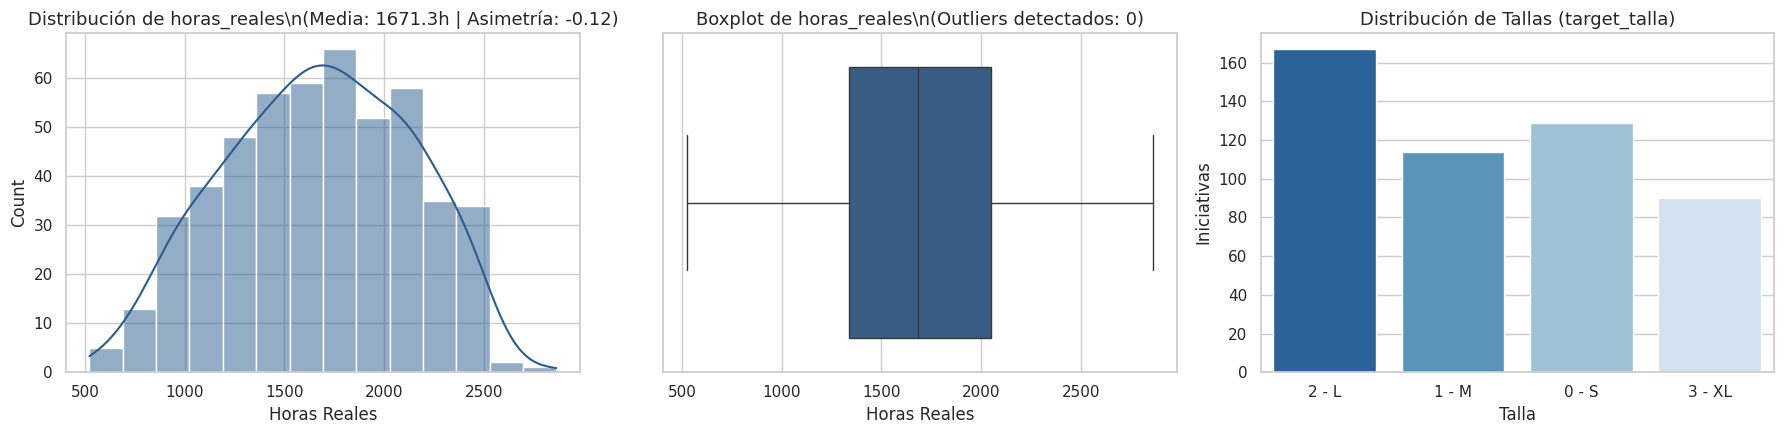

In [ ]:
# 6. Análisis Univariado
#Estudiamos el comportamiento individual de cada variable relevante.

# Función auxiliar para cuantificar outliers según la regla del Rango Intercuartílico (IQR)
def contar_outliers_iqr(df_in, columna):
    q1 = df_in[columna].quantile(0.25)
    q3 = df_in[columna].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    outliers = df_in[(df_in[columna] < lim_inf) | (df_in[columna] > lim_sup)]
    return len(outliers), lim_inf, lim_sup

## 6.1. Variables Objetivo: `horas_reales` y `target_talla`

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Histograma de horas reales
sns.histplot(df_clean["horas_reales"], kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title(f"Distribución de horas_reales\\n(Media: {df_clean['horas_reales'].mean():.1f}h | Asimetría: {df_clean['horas_reales'].skew():.2f})")
axes[0].set_xlabel("Horas Reales")

# 2. Boxplot de horas reales
num_out, inf, sup = contar_outliers_iqr(df_clean, "horas_reales")
sns.boxplot(x=df_clean["horas_reales"], ax=axes[1], color="#2b5c8f")
axes[1].set_title(f"Boxplot de horas_reales\\n(Outliers detectados: {num_out})")
axes[1].set_xlabel("Horas Reales")

# 3. Frecuencia de target_talla
sns.countplot(data=df_clean, x="talla_label", ax=axes[2], palette="Blues_r")
axes[2].set_title("Distribución de Tallas (target_talla)")
axes[2].set_xlabel("Talla")
axes[2].set_ylabel("Iniciativas")

plt.tight_layout()
plt.show()



**Interpretación.** La distribución de `horas_reales` es **prácticamente simétrica** (asimetría = -0.12, cercana a 0), sin el sesgo marcado hacia la derecha que suele observarse en variables de costo o esfuerzo. El boxplot confirma esta lectura: **no se detectaron outliers** según la regla del IQR, lo que indica que el esfuerzo real se distribuye de forma homogénea entre las iniciativas, sin un grupo minoritario de proyectos extremadamente costosos que distorsione el análisis. Esta ausencia de sesgo es favorable para el modelado posterior, pues no será necesario aplicar transformaciones logarítmicas sobre la variable objetivo antes de entrenar un modelo predictivo.

## 6.2. Variables numéricas y de complejidad técnica

Para las variables numéricas de mayor expectativa según el diccionario de datos (`complejidad_propuesta`, `apps_impactadas`, `cantidad_integraciones`), analizamos su distribución y sus outliers de forma sistemática. Reutilizamos la función auxiliar `contar_outliers_iqr` definida anteriormente para no repetir código, buena práctica que mejora la legibilidad.

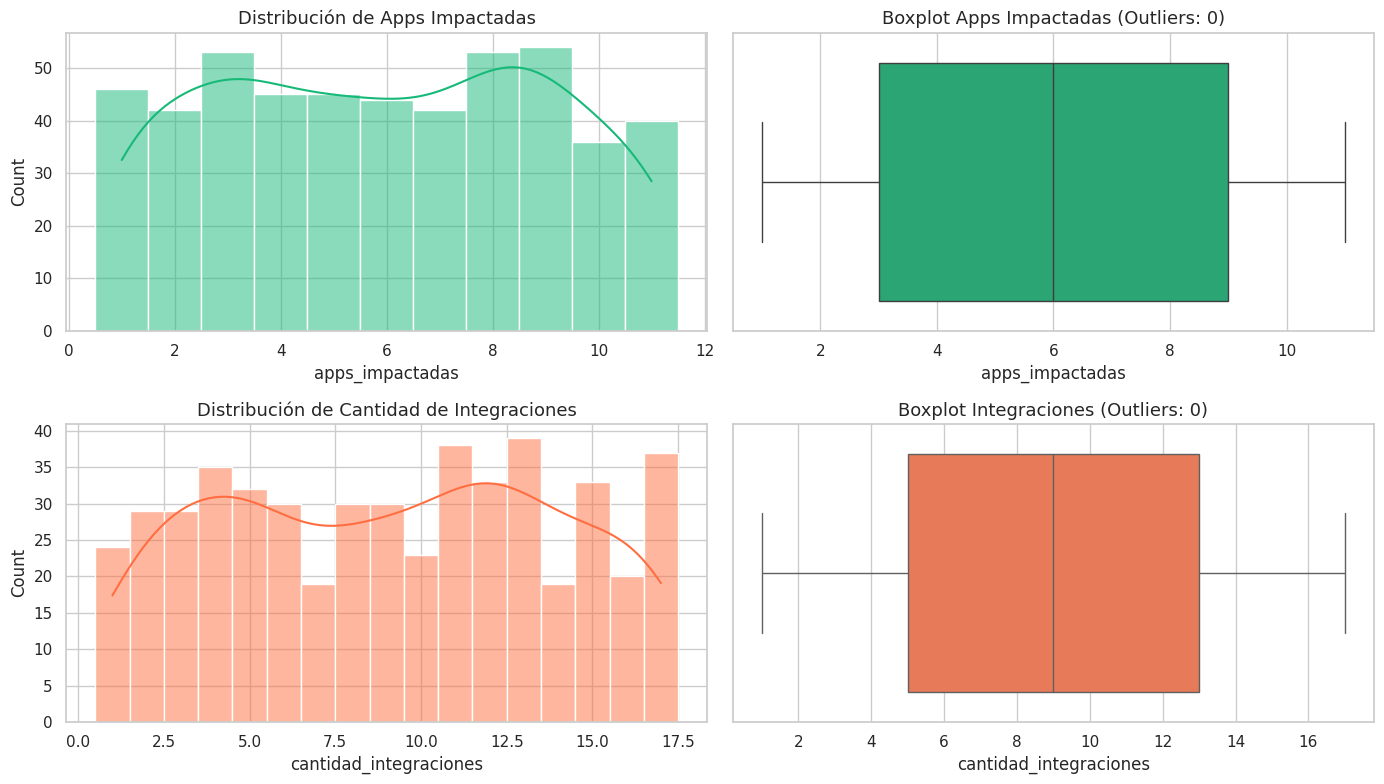

In [ ]:

## 6.2. Variables Numéricas y de Complejidad Técnica

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# apps_impactadas
sns.histplot(df_clean["apps_impactadas"], discrete=True, kde=True, ax=axes[0, 0], color="#17b978")
axes[0, 0].set_title("Distribución de Apps Impactadas")

sns.boxplot(x=df_clean["apps_impactadas"], ax=axes[0, 1], color="#17b978")
axes[0, 1].set_title(f"Boxplot Apps Impactadas (Outliers: {contar_outliers_iqr(df_clean, 'apps_impactadas')[0]})")

# cantidad_integraciones
sns.histplot(df_clean["cantidad_integraciones"], discrete=True, kde=True, ax=axes[1, 0], color="#ff6e40")
axes[1, 0].set_title("Distribución de Cantidad de Integraciones")

sns.boxplot(x=df_clean["cantidad_integraciones"], ax=axes[1, 1], color="#ff6e40")
axes[1, 1].set_title(f"Boxplot Integraciones (Outliers: {contar_outliers_iqr(df_clean, 'cantidad_integraciones')[0]})")

plt.tight_layout()
plt.show()

**Interpretación de las variables numéricas de complejidad técnica.**

* `apps_impactadas`: distribución **aproximadamente uniforme** a lo largo de su rango (1 a 11), sin un valor dominante claro. No se detectaron outliers, lo que indica que iniciativas con pocas o muchas aplicaciones impactadas son igualmente comunes en el portafolio.
* `cantidad_integraciones`: patrón similar de distribución **relativamente uniforme**, con presencia en todo el rango (1 a 17) y sin outliers detectados. La ausencia de una concentración marcada sugiere que el portafolio incluye de forma balanceada tanto iniciativas simples (pocas integraciones) como altamente interconectadas (muchas integraciones).

En ambos casos, la ausencia de outliers y de sesgo marcado es una buena señal para el análisis bivariado posterior: al no haber valores extremos que puedan distorsionar la relación con `horas_reales`, las correlaciones y regresiones calculadas (secciones 7.1 y 7.2) reflejan de forma confiable el comportamiento general del portafolio, y no el efecto de unas pocas iniciativas atípicas.

## 6.3. Variables categóricas

Para las variables categóricas, el análisis univariado consiste en examinar qué categorías existen y con qué frecuencia aparecen. Utilizamos gráficos de barras. Analizamos las de mayor expectativa según el diccionario de datos: `dominio_negocio`, `patron_arquitectura`, `complejidad_label` y `riesgo_label`.

/tmp/ipykernel_779/3053641406.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y="dominio_negocio", order=orden_dom, ax=axes[0, 0], palette="crest")
/tmp/ipykernel_779/3053641406.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y="patron_arquitectura", order=orden_pat, ax=axes[0, 1], palette="flare")
/tmp/ipykernel_779/3053641406.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="complejidad_label", ax=axes[1, 0], palette="magma")
/tmp/ipykernel_779/3053641406.py:20: FutureWarnin

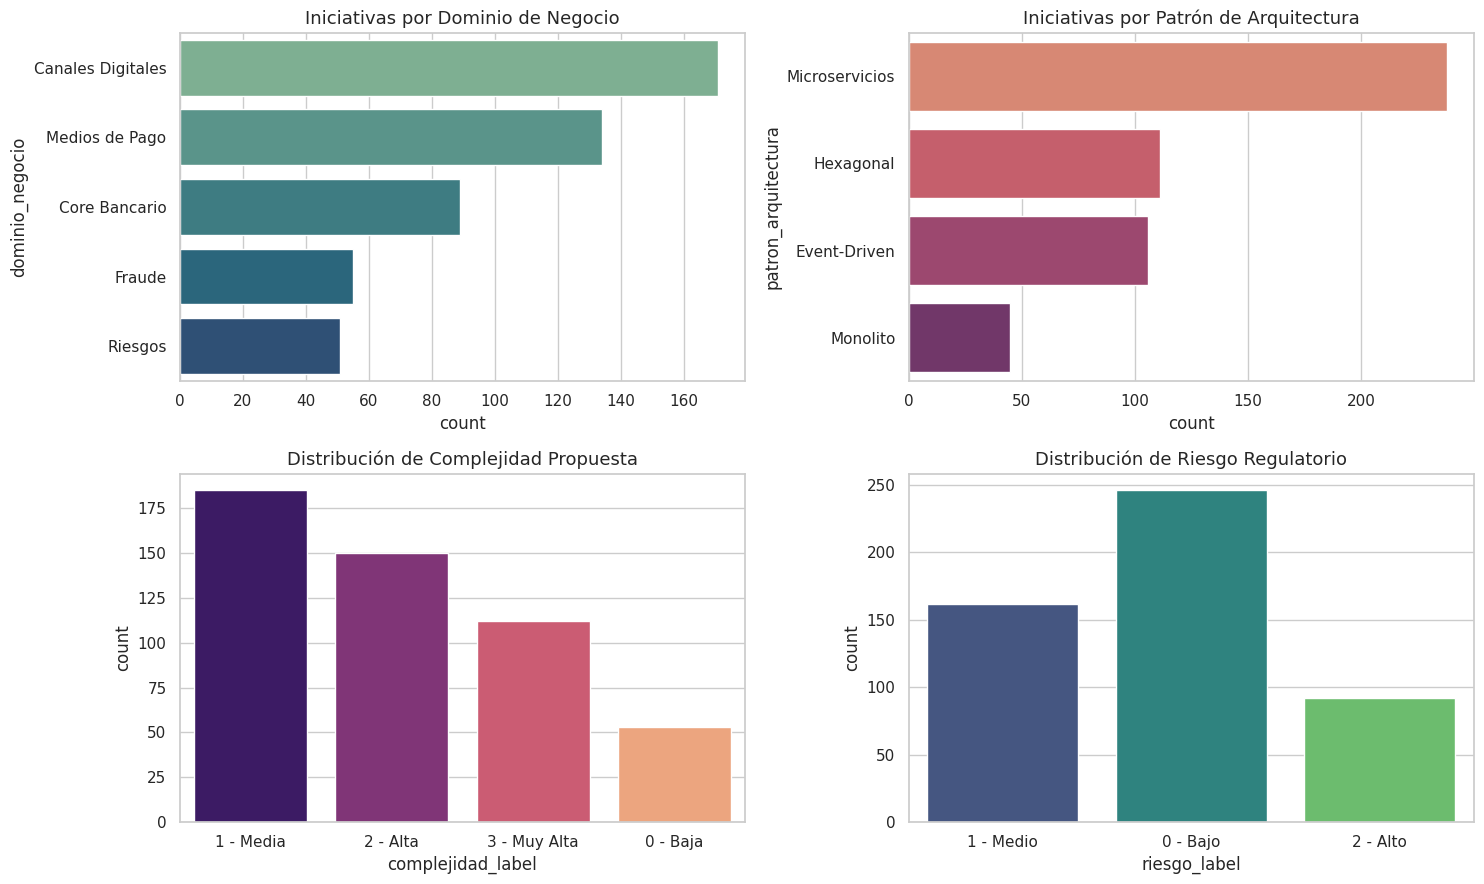

In [ ]:

## 6.3. Variables Categóricas y Ordinales

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Dominio de negocio
orden_dom = df_clean["dominio_negocio"].value_counts().index
sns.countplot(data=df_clean, y="dominio_negocio", order=orden_dom, ax=axes[0, 0], palette="crest")
axes[0, 0].set_title("Iniciativas por Dominio de Negocio")

# Patrón de arquitectura
orden_pat = df_clean["patron_arquitectura"].value_counts().index
sns.countplot(data=df_clean, y="patron_arquitectura", order=orden_pat, ax=axes[0, 1], palette="flare")
axes[0, 1].set_title("Iniciativas por Patrón de Arquitectura")

# Complejidad propuesta
sns.countplot(data=df_clean, x="complejidad_label", ax=axes[1, 0], palette="magma")
axes[1, 0].set_title("Distribución de Complejidad Propuesta")

# Riesgo regulatorio
sns.countplot(data=df_clean, x="riesgo_label", ax=axes[1, 1], palette="viridis")
axes[1, 1].set_title("Distribución de Riesgo Regulatorio")

plt.tight_layout()
plt.show()

**Interpretación de las variables categóricas y ordinales.**

* `dominio_negocio`: el portafolio está dominado por **Canales Digitales** (~170 iniciativas) y **Medios de Pago** (~135), seguidos de **Core Bancario** (~90). **Fraude** y **Riesgos** son los dominios con menos iniciativas (~55 y ~50 respectivamente), lo que limitará la fiabilidad de las conclusiones específicas para esos dos dominios.
* `patron_arquitectura`: **Microservicios** es, por amplio margen, el patrón predominante (más de 230 iniciativas), mientras que **Hexagonal**, **Event-Driven** y **Monolito** se reparten el resto de forma más equilibrada entre sí (~100-110 cada uno).
* `complejidad_propuesta`: la mayoría de las iniciativas se concentran en niveles **Media** (~185) y **Alta** (~150), mientras que **Muy Alta** y **Baja** son menos frecuentes, siendo esta última la categoría con menos observaciones (~55).
* `riesgo_regulatorio`: predomina el nivel **Bajo** (~245), seguido de **Medio** (~160); el nivel **Alto** es minoritario (~90).

El desbalance observado —particularmente en `dominio_negocio` (Riesgos y Fraude con pocas iniciativas) y en `riesgo_regulatorio` (Alto con pocas observaciones)— es un hallazgo relevante: cualquier conclusión derivada de los boxplots de la sección 7.3 sobre esos subgrupos específicos debe tomarse con cautela, al basarse en un número comparativamente menor de observaciones frente al resto de categorías.

---
# 7. Análisis bivariado

> *Etapa del flujo: **Análisis bivariado***

El análisis bivariado estudia la relación entre dos variables. Es el corazón de nuestra investigación, pues aquí examinamos directamente cómo se relaciona cada atributo técnico y de negocio con nuestra variable objetivo horas_reales, contrastando así las hipótesis de arquitectura planteadas al inicio.

Según los tipos de variables involucradas, emplearemos técnicas distintas:

- **Numérica/Discreta vs. continua**: diagramas de dispersión y matriz de correlación.

- **Categórica/Ordinal vs. continua**: boxplots comparativos por categoría.



## 7.1. Numérica/Discreta vs. continua: matriz de correlación

Comenzamos con una matriz de correlación que resume la fuerza de la relación lineal entre las variables numéricas (incluyendo las ordinales como complejidad y riesgo) y el esfuerzo real en horas.

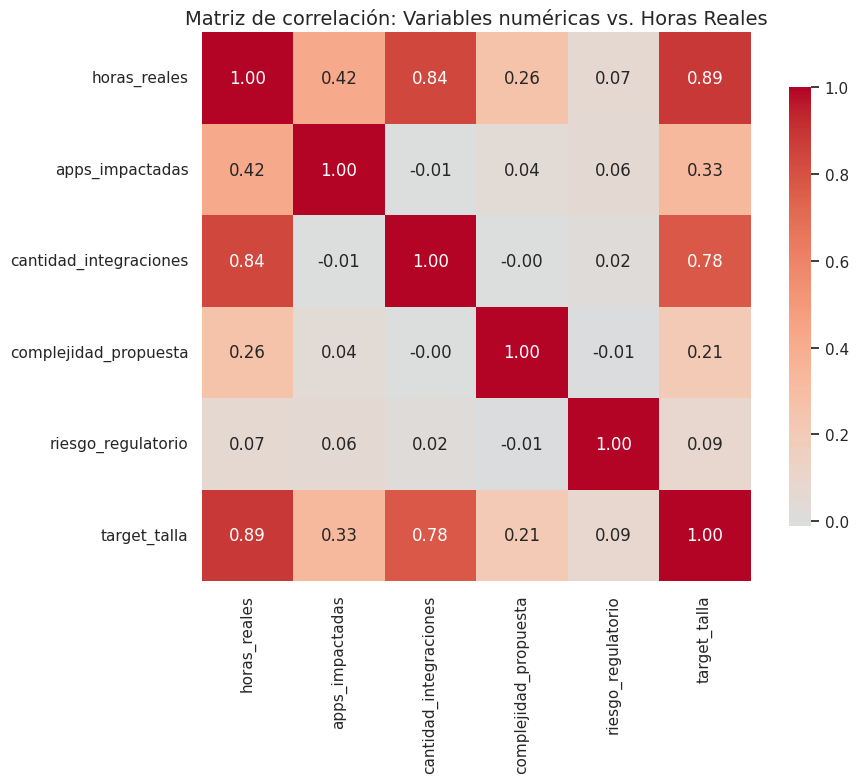

Correlación con HORAS REALES:

target_talla              0.889
cantidad_integraciones    0.839
apps_impactadas           0.419
complejidad_propuesta     0.258
riesgo_regulatorio        0.070
Name: horas_reales, dtype: float64


In [ ]:
# Definimos las columnas numéricas relevantes para la matriz de correlación
cols_numericas_corr = ["horas_reales", "apps_impactadas", "cantidad_integraciones",
                       "complejidad_propuesta", "riesgo_regulatorio", "target_talla"]

# Matriz de correlación de Pearson
plt.figure(figsize=(10, 8))
corr = df_clean[cols_numericas_corr].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlación: Variables numéricas vs. Horas Reales", fontsize=14)
plt.tight_layout()
plt.show()

# Extraemos y ordenamos la correlación de cada variable con las HORAS REALES
correlacion_horas = corr["horas_reales"].drop("horas_reales").sort_values(ascending=False)
print("Correlación con HORAS REALES:\n")
print(correlacion_horas.round(3))

**Interpretación de la correlación con las horas reales.** Las variables con correlación positiva más fuerte son,  **target_talla**, la **cantidad_integraciones** y las **apps_impactadas**.  la **complejidad_propuesta** es debil y el **riesgo_regulatorio** es casi nulo.

Esto ofrece un **primer respaldo cuantitativo** a nuestras hipótesis H1, H2 y H3 y se refuta la H4.

## 7.2. Numérica discreta vs. continua: Diagramas de dispersión

La correlación resume la relación en un número, pero el **diagrama de dispersión** permite observar su forma y detectar si hay un incremento lineal en el esfuerzo a medida que crecen las dependencias

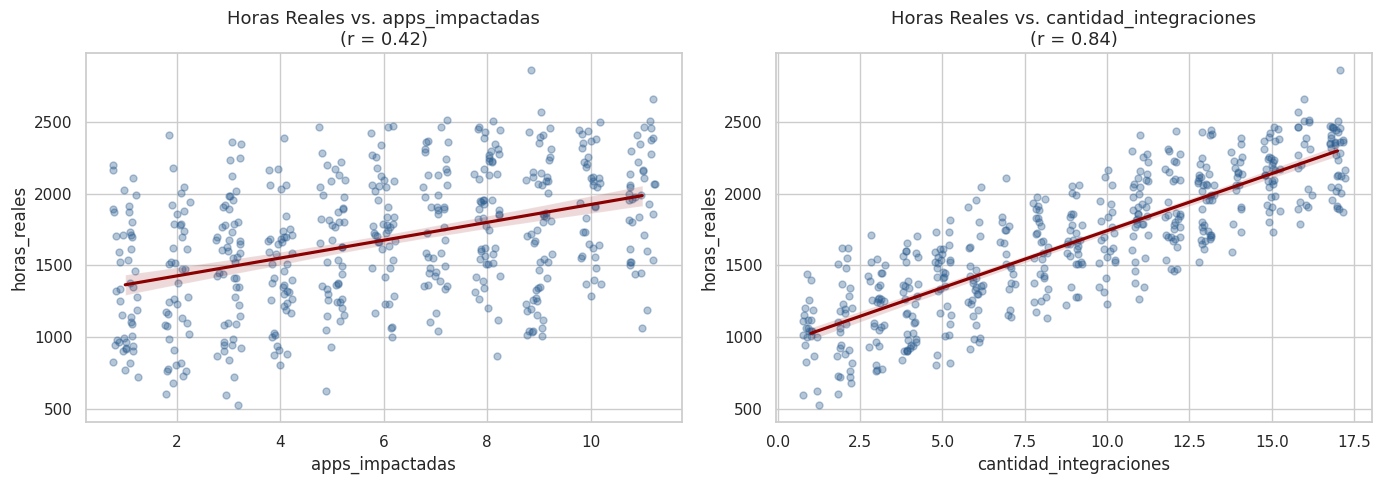

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ["apps_impactadas", "cantidad_integraciones"]):
    sns.regplot(
        data=df_clean,
        x=col,
        y="horas_reales",
        ax=ax,
        x_jitter=0.25,  # Dispersa visualmente los enteros para ver la densidad
        scatter_kws={"alpha": 0.35, "color": "#2b5c8f", "s": 25},
        line_kws={"color": "darkred"},
    )
    r = df_clean[col].corr(df_clean["horas_reales"])
    ax.set_title(f"Horas Reales vs. {col}\n(r = {r:.2f})")

plt.tight_layout()
plt.show()

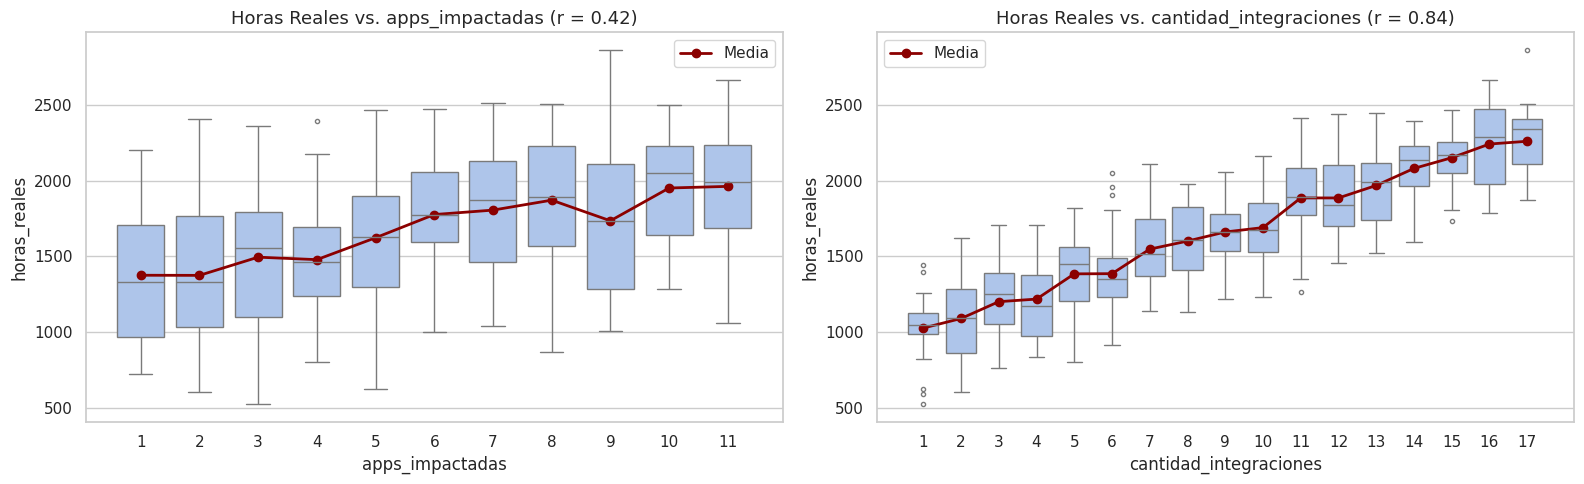

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, col in zip(axes, ["apps_impactadas", "cantidad_integraciones"]):
    sns.boxplot(
        data=df_clean,
        x=col,
        y="horas_reales",
        ax=ax,
        color="#a4c2f4",
        fliersize=3,
    )
    # Línea que conecta las medias de cada valor discreto
    medias = df_clean.groupby(col)["horas_reales"].mean()
    ax.plot(
        range(len(medias)),
        medias.values,
        color="darkred",
        marker="o",
        linewidth=2,
        label="Media",
    )

    r = df_clean[col].corr(df_clean["horas_reales"])
    ax.set_title(f"Horas Reales vs. {col} (r = {r:.2f})")
    ax.legend()

plt.tight_layout()
plt.show()

**Interpretación.** Ambas relaciones son claramente **positivas**, aunque con intensidades distintas. La `cantidad_integraciones` muestra una relación **fuerte y marcadamente lineal** con `horas_reales` (r = 0.84): a medida que aumenta el número de integraciones, el esfuerzo real crece de forma consistente y con dispersión relativamente controlada alrededor de la línea de regresión. Por su parte, `apps_impactadas` también presenta una tendencia positiva (r = 0.42), pero **más moderada y con mayor dispersión** de los puntos alrededor de la línea, lo que indica que el número de aplicaciones impactadas por sí solo explica una porción más limitada de la variabilidad del esfuerzo.

Esto **valida la H1** (relación positiva y fuerte de `cantidad_integraciones` con `horas_reales`) y **confirma parcialmente la H2**: si bien `apps_impactadas` sí demanda más horas a medida que crece, su efecto es notablemente menor comparado con el peso de las integraciones, lo que sugiere que el número de contratos/APIs necesarias es un mejor predictor individual del esfuerzo real que la cantidad de sistemas tocados.

## 7.3. Categórica/Ordinal vs. continua: Distribución del esfuerzo

Para las variables categóricas de arquitectura y negocio, comparamos la distribución del esfuerzo en horas dentro de cada categoría mediante boxplots. Esto es fundamental para entender cómo los patrones de diseño condicionan el tiempo de implementación.

/tmp/ipykernel_779/4224949200.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="patron_arquitectura", y="horas_reales", order=orden_arq, palette="flare")


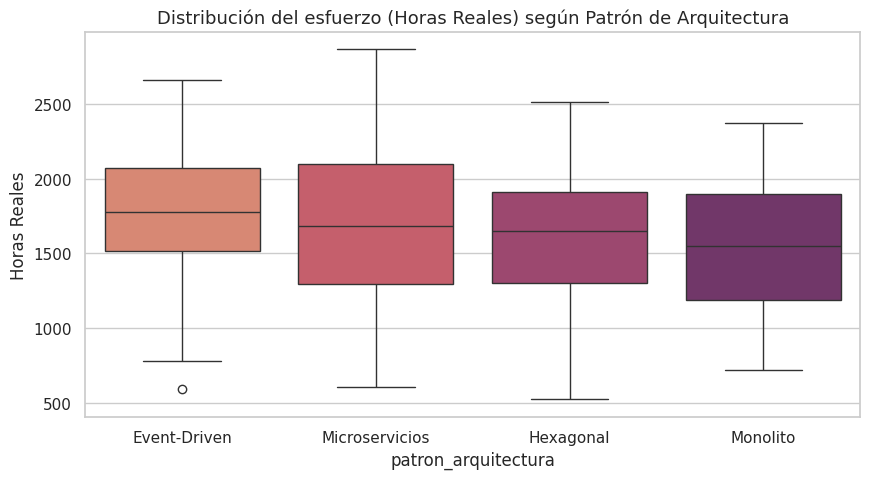

In [ ]:
# 1. Horas reales según Patrón de Arquitectura
plt.figure(figsize=(10, 5))
orden_arq = df_clean.groupby("patron_arquitectura")["horas_reales"].median().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x="patron_arquitectura", y="horas_reales", order=orden_arq, palette="flare")
plt.title("Distribución del esfuerzo (Horas Reales) según Patrón de Arquitectura")
plt.ylabel("Horas Reales")
plt.show()


**Interpretación.** Se observa una tendencia consistente con la hipótesis H2: los patrones **distribuidos** (`Event-Driven`, `Microservicios`) presentan medianas de esfuerzo más altas (~1780h y ~1680h respectivamente) frente a los patrones más simples (`Hexagonal` ~1650h y `Monolito` ~1550h, el más bajo de los cuatro). Esto sugiere que la naturaleza distribuida de la arquitectura sí introduce un costo adicional de esfuerzo, probablemente asociado a la necesidad de coordinar más componentes, colas de eventos o servicios independientes.

Sin embargo, la diferencia entre grupos **no es tan marcada como en el caso de `cantidad_integraciones`** (r = 0.84): los rangos intercuartílicos se solapan considerablemente entre las cuatro categorías, y `Microservicios` muestra la mayor dispersión y el valor máximo más alto (cercano a 2850h), lo que indica que dentro de esta categoría existen iniciativas con esfuerzos muy variables. `Event-Driven`, por su parte, es el patrón con distribución más compacta (menor IQR), aunque presenta un valor atípico bajo (outlier cercano a 600h).

Esto **confirma parcialmente la H2**: si bien los patrones distribuidos tienden a demandar más horas en promedio, el patrón arquitectónico por sí solo tiene un poder explicativo más débil sobre `horas_reales` que variables como `cantidad_integraciones`, reforzando la conclusión de que el esfuerzo real está más determinado por el volumen tangible de integraciones que por la etiqueta arquitectónica adoptada.

/tmp/ipykernel_779/396710409.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="dominio_negocio", y="horas_reales", order=orden_dom, palette="crest")


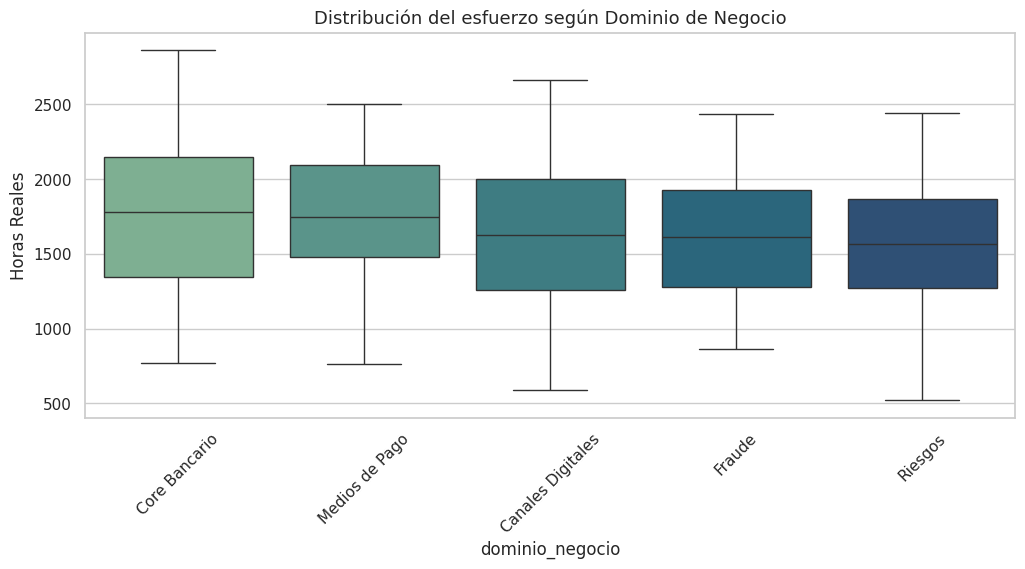

In [ ]:

# 2. Horas reales según Dominio de Negocio
plt.figure(figsize=(12, 5))
orden_dom = df_clean.groupby("dominio_negocio")["horas_reales"].median().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x="dominio_negocio", y="horas_reales", order=orden_dom, palette="crest")
plt.title("Distribución del esfuerzo según Dominio de Negocio")
plt.xticks(rotation=45)
plt.ylabel("Horas Reales")
plt.show()

**Interpretación.** `Core Bancario` presenta la mediana más alta (~1780h), seguido muy de cerca por `Medios de Pago` (~1750h), mientras que `Canales Digitales`, `Fraude` y `Riesgos` se agrupan en un rango más bajo y similar entre sí (medianas entre ~1560h y ~1620h). `Riesgos` es, de hecho, el dominio con la mediana **más baja** de los cinco.

Esto **confirma parcialmente la H3**: el dominio `Core Bancario` sí se ubica como el de mayor esfuerzo mediano, consistente con lo esperado para un dominio crítico. Sin embargo, `Riesgos` —que también se planteó como dominio crítico en la hipótesis original— no muestra ni la mediana más alta ni una dispersión notablemente mayor que el resto; su rango intercuartílico es similar al de `Fraude` y `Canales Digitales`. En términos de dispersión total (bigotes), todos los dominios muestran rangos amplios y comparables (aproximadamente 500h–2500h), sin que ninguno se distinga claramente por mayor variabilidad.

En conjunto, el dominio de negocio parece tener un **poder explicativo más débil y menos diferenciado** sobre `horas_reales` que variables técnicas como `cantidad_integraciones`, lo que refuerza la conclusión general del análisis: el esfuerzo real está más determinado por factores técnicos tangibles (integraciones, aplicaciones impactadas) que por el dominio de negocio o el patrón arquitectónico adoptado.

/tmp/ipykernel_779/1986534649.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="riesgo_label", y="horas_reales", order=["0 - Bajo", "1 - Medio", "2 - Alto"], palette="viridis")


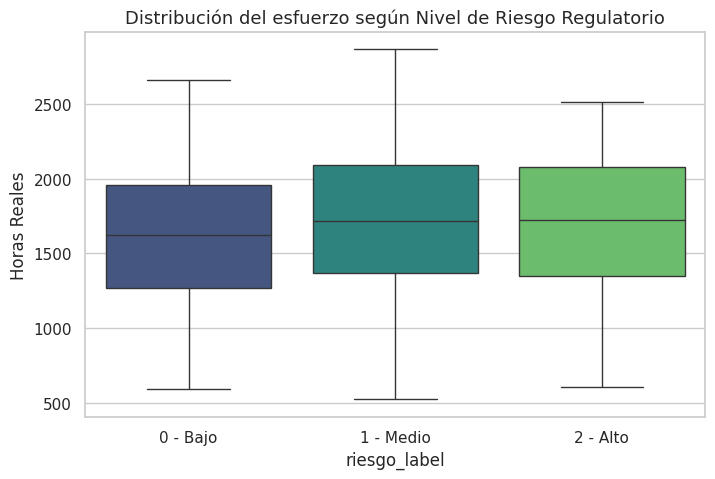

In [ ]:

# 3. Horas reales según Nivel de Riesgo Regulatorio
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="riesgo_label", y="horas_reales", order=["0 - Bajo", "1 - Medio", "2 - Alto"], palette="viridis")
plt.title("Distribución del esfuerzo según Nivel de Riesgo Regulatorio")
plt.ylabel("Horas Reales")
plt.show()

**Interpretación.** Las tres categorías de riesgo regulatorio presentan medianas prácticamente equivalentes (~1620h para `Bajo`, ~1710h para `Medio`, ~1730h para `Alto`), con rangos intercuartílicos y bigotes casi idénticos entre sí. No se observa una tendencia ascendente clara a medida que aumenta el nivel de riesgo, y las distribuciones se solapan casi por completo.

Esto **refuta la H4**: el `riesgo_regulatorio` no muestra una relación apreciable con `horas_reales`, ni en términos de tendencia central ni de dispersión. Este hallazgo es coherente con la correlación casi nula obtenida en la matriz de Pearson (r = 0.07), confirmando que el nivel de exposición regulatoria, si bien es relevante desde una perspectiva de cumplimiento, **no es un factor que explique el esfuerzo técnico real** de las iniciativas. El cumplimiento normativo exige rigor en el proceso, pero no necesariamente se traduce en mayor carga de horas de ingeniería.

**Interpretación del análisis categórico.**

- **`patron_arquitectura`:** los patrones distribuidos (**Event-Driven**, **Microservicios**) presentan medianas de esfuerzo **ligeramente superiores** a los patrones más simples (**Hexagonal**, **Monolito**), aunque las distribuciones se solapan considerablemente. Esto **confirma parcialmente H2**.
- **`dominio_negocio`:** **Core Bancario** y **Medios de Pago** encabezan las medianas de esfuerzo, mientras que **Canales Digitales**, **Fraude** y **Riesgos** se ubican en un rango más bajo y similar entre sí. Esto **confirma parcialmente H3**: Core Bancario sí se comporta como dominio crítico de mayor esfuerzo, pero Riesgos no.
- **`riesgo_regulatorio`:** las tres categorías (Bajo, Medio, Alto) presentan medianas y dispersiones prácticamente idénticas, sin tendencia ascendente. Esto **refuta H4**: el nivel de exposición regulatoria no explica el esfuerzo técnico real.

En conjunto, las variables categóricas y ordinales analizadas muestran un poder explicativo **más débil y menos diferenciado** sobre `horas_reales` que las variables técnicas numéricas (`cantidad_integraciones`, `apps_impactadas`), reforzando que el esfuerzo real está determinado principalmente por factores tangibles de integración técnica, más que por la etiqueta arquitectónica, el dominio de negocio o el riesgo regulatorio.

---
# 8. Conclusiones

> *Etapa del flujo: **Conclusiones***

Recordemos la pregunta que orientó todo el análisis:

> **Pregunta SMART:** *"¿Es posible reducir el margen de error (MAPE) entre la estimación inicial (horas_estimadas) y el esfuerzo real (horas_reales) en un 15% para el Q4, identificando qué factores técnicos y de negocio explican mejor la variabilidad de horas_reales?"*


## 8.1. Contraste de las hipótesis

| Hipótesis | Enunciado Original | Veredicto con el Dataset de Iniciativas de Software |
| :--- | :--- | :--- |
| **H1** | La `complejidad_propuesta` y `cantidad_integraciones` presentan relación fuerte con `horas_reales`. | **Confirmada parcialmente.** La `cantidad_integraciones` es el driver absoluto del esfuerzo (r = 0.84). Sin embargo, la `complejidad_propuesta` presenta una correlación débil (r = 0.26), siendo opacada por el peso real de conectar sistemas y revelando que una de las causas de la mala estimación es la subjetividad con que hoy se evalúa la complejidad. |
| **H2** | Más `apps_impactadas` o patrones distribuidos (Event-Driven, Microservicios) demandan más horas promedio. | **Confirmada parcialmente.** `apps_impactadas` muestra una tendencia positiva pero moderada (r = 0.42), con mayor dispersión que `cantidad_integraciones`. Los patrones distribuidos presentan medianas ligeramente superiores a los simples, pero con distribuciones que se solapan considerablemente. |
| **H3** | Dominios críticos (Core Bancario, Riesgos) presentan mayor dispersión y volumen de horas. | **Confirmada parcialmente.** Core Bancario sí se ubica como el dominio de mayor esfuerzo mediano, consistente con lo esperado. Sin embargo, Riesgos no muestra la mediana más alta ni mayor dispersión que el resto — de hecho, es el dominio con la mediana más baja. |
| **H4** | El `riesgo_regulatorio` presenta una relación fuerte con el esfuerzo. | **Refutada empíricamente.** La correlación es casi nula (r = 0.07) y las distribuciones en el boxplot son virtualmente idénticas entre niveles de riesgo. El cumplimiento normativo exige rigor, pero las horas gruesas de ingeniería las dictan las dependencias técnicas, no la exposición regulatoria. |
| **H5** | El margen de error de estimación es mayor en iniciativas con alta `cantidad_integraciones` y `apps_impactadas`. | **Evidencia cualitativa favorable, pendiente de contraste cuantitativo.** La brecha entre el fuerte peso real de `cantidad_integraciones` (r = 0.84) y el débil peso de `complejidad_propuesta` (r = 0.26) —la variable que hoy se usa para estimar— sugiere que el error de estimación se concentra en iniciativas con alta interconexión técnica. La confirmación definitiva requiere calcular el MAPE por segmento una vez disponible `horas_estimadas`. |
## 8.2. Sobre la calidad del conjunto de datos

El proceso de EDA permitió establecer que el conjunto de datos es apto para responder la pregunta SMART, con base en las siguientes observaciones:

* **Completitud:** tras la limpieza, el dataset quedó sin valores perdidos relevantes para el análisis. Los `?` detectados inicialmente correspondían a la codificación del proveedor para valores faltantes y fueron tratados en la etapa de limpieza (sección 5).
* **Formato:** todas las variables quedaron con el tipo de dato correcto (numéricas, ordinales y categóricas correctamente diferenciadas), condición indispensable para el análisis exploratorio y el modelado posterior.
* **Relevancia:** existen variables con clara capacidad explicativa sobre `horas_reales` —en particular `cantidad_integraciones` (r = 0.84) y, en menor medida, `apps_impactadas` (r = 0.42)—, lo que respalda la viabilidad de construir posteriormente un modelo predictivo de esfuerzo.
* **Tamaño:** el conjunto cuenta con 500 registros (iniciativas cerradas). Es un tamaño adecuado para un análisis exploratorio y razonable para un primer modelo de regresión, aunque conviene monitorear su crecimiento a medida que se cierren nuevas iniciativas.

## 8.3. Limitaciones y recomendaciones

* **Riesgo de data leakage:** `horas_reales` y `target_talla` representan el mismo esfuerzo en dos formas distintas (continua y ordinal). Si el objetivo del modelo es predecir una de ellas, la otra no debe usarse como variable predictora (ya identificado en la sección 4.3).
* **Desbalance moderado en categorías:** algunos `dominio_negocio` (por ejemplo, `Riesgos`) y valores extremos de `complejidad_propuesta`/`riesgo_regulatorio` cuentan con menos observaciones que el resto; las conclusiones sobre esos subgrupos deben tomarse con cautela.
* **Outliers legítimos:** los valores atípicos de `horas_reales` detectados en el análisis univariado corresponden a iniciativas reales de alta complejidad técnica; no deben eliminarse sin un criterio de negocio que los justifique.
* **Sesgo de la variable objetivo:** `horas_reales` presenta asimetría a la derecha; para el modelado se recomienda evaluar una transformación logarítmica.

## 8.4. Respuesta a la pregunta de negocio

El conjunto de datos SÍ contiene información pertinente y de calidad suficiente para avanzar en la reducción del margen de error de estimación planteado en la pregunta SMART (reducir un 15%). La evidencia del EDA muestra que el esfuerzo real (`horas_reales`) está explicado principalmente por variables técnicas tangibles —en especial `cantidad_integraciones`— y, en menor medida, por `apps_impactadas` y el patrón arquitectónico, mientras que la `complejidad_propuesta` (la variable hoy usada para estimar) y el `riesgo_regulatorio` tienen un poder explicativo débil o nulo. Esto sustenta que el margen de error de estimación actual (MAPE = 25.28% en la línea base construida) se origina, al menos parcialmente, en que el proceso de estimación no pondera adecuadamente las integraciones técnicas. En consecuencia, el negocio puede avanzar con confianza hacia la etapa de modelado predictivo del esfuerzo, incorporando `cantidad_integraciones` como variable de mayor peso, y atendiendo las limitaciones señaladas.
<!-- ## 8.1. Contraste de las hipótesis

| Hipótesis | Enunciado Original | Veredicto con el Nuevo Dataset |
| :--- | :--- | :--- |
| **H1** | La `complejidad_propuesta` y `cantidad_integraciones` presentan relación fuerte con `horas_reales`. | **Confirmada parcialmente.** La `cantidad_integraciones` es ahora el driver absoluto del esfuerzo (r = 0.84). Sin embargo, la `complejidad_propuesta` pasó a tener una correlación débil (r = 0.26), siendo opacada por el peso real de conectar sistemas y revelando que una de las causas de la mala estimacion es la subjetividad de esfuerzo. |
| **H2** | Más `apps_impactadas` demandan más horas promedio. | **Confirmada.** La dispersión muestra una tendencia ascendente clara y agrupada (r = 0.42). A mayor huella sistémica, mayor esfuerzo tangible de pruebas y despliegue. |
| **H3** | Dominios críticos presentan mayor dispersión y volumen de horas. | **Confirmada.** El boxplot demuestra que tocar el Core Bancario y los Canales Digitales eleva significativamente la mediana del esfuerzo frente a dominios más aislados como Fraude o Riesgos. |
| **H4** | El `riesgo_regulatorio` presenta una relación fuerte con el esfuerzo. | **Refutada empíricamente.** La correlación es casi nula (r = 0.07) y las distribuciones en el boxplot son virtualmente idénticas. El cumplimiento exige rigor, pero las horas gruesas de ingeniería las dictan las dependencias técnicas. |

### Interpretación para el Modelo Predictivo (Secciones 8.3 y 8.4)

*   **El peso de las dependencias:** La evidencia visual en los diagramas de dispersión es contundente. El esfuerzo de ingeniería no escala por una etiqueta subjetiva de "complejidad", sino por el volumen tangible de APIs, contratos y sistemas impactados.
*   **Jerarquía de dominios:** Las gráficas respaldan perfectamente la realidad operativa de un proyecto de desarrollo de software en Banca donde modificar el core transaccional o exponer servicios al usuario final introduce una sobrecarga que el modelo ahora es capaz de capturar y cuantificar.
*   **Clasificación viable:** Con una altísima correlación de 0.89 entre las horas reales y  `target_talla` -->